# MASSPEC (1970), step by step

Margaret O. Dayhoff and Richard V. Eck, "MASSPEC: A computer program for complete sequence analysis
of large proteins from mass spectrometry data of a single sample", *Computers in Biology and
Medicine* 1, 5-28 (1970), [doi:10.1016/0010-4825(70)90013-2](https://doi.org/10.1016/0010-4825(70)90013-2).

Their proposal: break a protein near-randomly (partial acid hydrolysis), make the fragments volatile,
and measure the whole mixture in **one** high-resolution mass spectrum. An exact mass fixes a
fragment's elemental formula but not its sequence, nor even its amino acid composition (Ala-Val and
Gly-Leu weigh the same). The sequence is recovered as the one set of overlapping fragments that is
mutually consistent among the thousands of spurious candidates the same masses also allow.

They demonstrated it on simulated, ideal data for bovine insulin. This notebook redoes that
experiment with the reimplementation in this repository (`src/masspec`), one program at a time, and
regenerates each figure of the paper next to the values the paper prints. **The code is a
reimplementation from the paper's description, not the original program, which appears to be lost.**

The paper's one-letter code is used throughout: **J** is leucine or isoleucine (they weigh the same,
so the method cannot tell them apart) and **O** is tyrosine.

In [1]:
from collections import Counter
from itertools import combinations_with_replacement

import matplotlib.pyplot as plt

from masspec.fragments import add_noise, fragen, ideal_masses
from masspec.masses import H2O_1970, MASSES, MASSES_1970, _FREE_1970
from masspec.mspec import Observed, canon, cq, masfrg, overlap_step, prune, run

T, W = MASSES_1970, H2O_1970
mass = lambda s: sum(T[a] for a in s) + W          # peptide mass: residues plus one water
comp = lambda s: "".join(sorted(s))                # composition, letters in alphabetical order

A = "GJVEQCCASVCSJOQJENOCN"            # insulin A chain, bovine (21 residues)
B = "FVNQHJCGSHJVEAJOJVCGERGFFOTPKA"   # insulin B chain, bovine (30 residues)

## Fig. 2: the masses

The paper lists the monoisotopic masses of the free amino acids; a peptide weighs their sum minus one
water per peptide bond, which is the same as the sum of RESIDUE masses plus one water. Below, the
paper's values beside present-day ones (free amino acid = residue + water).

One entry is wrong in the paper: tryptophan is printed as 188.09489, but free tryptophan
(C11H12N2O2) weighs 204.0899. The program evidently ran on the printed value, because the counts in
Figs. 6-8 are only reproduced with it (see below). Insulin has no tryptophan, so the slip never showed.

In [2]:
modern = {"J": MASSES["L"], "O": MASSES["Y"], **MASSES}
print(f"{'':4}{'paper (free)':>14}{'present-day (free)':>20}{'difference':>12}")
for aa in sorted(_FREE_1970):
    now = modern[aa] + 18.0105647
    print(f"{aa:4}{_FREE_1970[aa]:14.5f}{now:20.5f}{_FREE_1970[aa] - now:12.5f}")

      paper (free)  present-day (free)  difference
A         89.04763            89.04768    -0.00005
C        121.01970           121.01975    -0.00005
D        133.03745           133.03751    -0.00006
E        147.05309           147.05316    -0.00007
F        165.07891           165.07898    -0.00007
G         75.03199            75.03203    -0.00004
H        155.06941           155.06948    -0.00007
J        131.09455           131.09463    -0.00008
K        146.10544           146.10553    -0.00009
M        149.05098           149.05105    -0.00007
N        132.05343           132.05349    -0.00006
O        181.07382           181.07389    -0.00007
P        115.06327           115.06333    -0.00006
Q        146.06907           146.06914    -0.00007
R        174.11158           174.11168    -0.00010
S        105.04254           105.04259    -0.00005
T        119.05818           119.05824    -0.00006
V        117.07891           117.07898    -0.00007
W        188.09489           20

## Fig. 1: FRAGEN, fragmenting the protein

FRAGEN simulates a random hydrolysis by listing every fragment of the chain. The masses will only
say what a fragment is MADE of, so the paper prints the amino acid composition of each, in
alphabetical order. Fig. 1 shows the 24 fragments seven residues long from the B chain (the paper
writes L for Leu here, J elsewhere).

In [3]:
seven = [B[i:i + 7] for i in range(len(B) - 6)]
for k, f in enumerate(seven, 1):
    print(f"{k:3}  {comp(f).replace('J', 'L')}")

  1  CFHLNQV
  2  CGHLNQV
  3  CGHLNQS
  4  CGHHLQS
  5  CGHHLLS
  6  CGHLLSV
  7  CEGHLSV
  8  AEGHLSV
  9  AEHLLSV
 10  AEHLLOV
 11  AELLLOV
 12  AELLOVV
 13  ACELLOV
 14  ACGLLOV
 15  CEGLLOV
 16  CEGLORV
 17  CEGGLRV
 18  CEFGGRV
 19  CEFFGGR
 20  EFFGGOR
 21  EFFGORT
 22  FFGOPRT
 23  FFGKOPT
 24  AFFKOPT


## Figs. 3 and 4: MASFRG, the masses of the fragments

MASFRG computes each fragment's mass. Fig. 3 lists the B chain's dipeptides, Fig. 4 its
octapeptides; the paper's values are copied below (its Fig. 4 prints "951 a48426" for row 15, an
OCR-legible smudge of 951.48426).

In [4]:
paper_fig3 = {"AE": 218.09016, "AK": 217.14251, "AJ": 202.13162, "CG": 178.04113, "CJ": 234.10369,
              "CV": 220.08805, "EG": 204.07452, "ER": 303.15411, "EV": 246.12144, "FF": 312.14725,
              "FG": 222.10034, "FO": 328.14217, "FV": 264.14726, "GR": 231.13301, "GS": 162.06397,
              "HJ": 268.15340, "HQ": 283.12791, "HS": 242.10139, "KP": 243.15815, "JO": 294.15781,
              "JV": 230.16290, "NQ": 260.11193, "NV": 231.12178, "OT": 282.12144, "PT": 216.11089}
dipeptides = sorted({comp(B[i:i + 2]) for i in range(len(B) - 1)})
print(f"{len(dipeptides)} distinct dipeptide compositions in B (paper: 25)\n")
print(f"{'':4}{'here':>12}{'paper':>12}{'diff':>10}")
for d in dipeptides:
    print(f"{d:4}{mass(d):12.5f}{paper_fig3[d]:12.5f}{mass(d) - paper_fig3[d]:10.5f}")

25 distinct dipeptide compositions in B (paper: 25)

            here       paper      diff
AE     218.09016   218.09016   0.00000
AJ     202.13162   202.13162   0.00000
AK     217.14251   217.14251   0.00000
CG     178.04113   178.04113   0.00000
CJ     234.10369   234.10369   0.00000
CV     220.08805   220.08805   0.00000
EG     204.07452   204.07452   0.00000
ER     303.15411   303.15411   0.00000
EV     246.12144   246.12144   0.00000
FF     312.14726   312.14725   0.00001
FG     222.10034   222.10034   0.00000
FO     328.14217   328.14217   0.00000
FV     264.14726   264.14726   0.00000
GR     231.13301   231.13301   0.00000
GS     162.06397   162.06397  -0.00000
HJ     268.15340   268.15340   0.00000
HQ     283.12792   283.12791   0.00001
HS     242.10139   242.10139   0.00000
JO     294.15781   294.15781   0.00000
JV     230.16290   230.16290  -0.00000
KP     243.15815   243.15815  -0.00000
NQ     260.11194   260.11193   0.00001
NV     231.12178   231.12178   0.00000
OT     282.

In [5]:
paper_fig4 = [916.42204, 856.38567, 894.37617, 893.41729, 864.42713, 856.41081, 814.36389, 824.43874,
              930.48057, 956.53258, 918.54208, 908.46723, 866.42031, 866.42031, 951.48426, 895.42170,
              879.42679, 913.41115, 977.40606, 975.44454, 1015.47582, 1014.52817, 929.46422]
eight = [B[i:i + 8] for i in range(len(B) - 7)]
print(f"{'':3}{'composition':>14}{'here':>12}{'paper':>12}{'diff':>10}")
for k, (f, p) in enumerate(zip(eight, paper_fig4), 1):
    print(f"{k:3}{comp(f):>14}{mass(f):12.5f}{p:12.5f}{mass(f) - p:10.5f}")

      composition        here       paper      diff
  1      CFGHJNQV   916.42205   916.42204   0.00001
  2      CGHJNQSV   856.38568   856.38567   0.00001
  3      CGHHJNQS   894.37618   894.37617   0.00001
  4      CGHHJJQS   893.41730   893.41729   0.00001
  5      CGHHJJSV   864.42714   864.42713   0.00001
  6      CEGHJJSV   856.41082   856.41081   0.00001
  7      ACEGHJSV   814.36390   814.36389   0.00001
  8      AEGHJJSV   824.43875   824.43874   0.00001
  9      AEHJJOSV   930.48058   930.48057   0.00001
 10      AEHJJJOV   956.53259   956.53258   0.00001
 11      AEJJJOVV   918.54209   918.54208   0.00001
 12      ACEJJOVV   908.46724   908.46723   0.00001
 13      ACEGJJOV   866.42032   866.42031   0.00001
 14      ACEGJJOV   866.42032   866.42031   0.00001
 15      CEGJJORV   951.48427   951.48426   0.00001
 16      CEGGJORV   895.42171   895.42170   0.00001
 17      CEFGGJRV   879.42680   879.42679   0.00001
 18      CEFFGGRV   913.41116   913.41115   0.00001
 19      CEF

Every dipeptide mass agrees with the paper exactly, and every octapeptide mass to one unit in the
fifth decimal: the paper's are uniformly one lower, as if the program truncated where Python rounds.
(Matching needed
one correction to the scanned mass table: arginine is 174.11158, not 174.11168 as the smudged Fig. 2
reads; every mass here that contains R confirms it.) The table also shows why the method is hard:
rows 13 and 14 are the same composition, and many different peptides share a mass.

## Fig. 5: PEPMS, the table of all peptide masses

To go back from a mass to what could have made it, the program needs every composition sorted by
mass. PEPMS tabulates them (only up to four residues: longer ones are generated later, from overlaps).
Fig. 5 shows the stretch from 506.24 to 507.27. Each line is a group of compositions with identical
formulas; the step column is the gap to the previous mass.

In [6]:
table = {}
for n in range(1, 5):
    for c in combinations_with_replacement(sorted(T), n):
        table.setdefault(round(mass(c), 5), []).append("".join(c))
prev = None
for m in sorted(x for x in table if 506.24 <= x <= 507.27):
    step = f"{m - prev:.5f}" if prev else ""
    print(f"{m:11.5f} {step:>9}   {' '.join(table[m])}")
    prev = m
print("\nANFR - TJHH =", f"{mass('ANFR') - mass('TJHH'):.5f}", "   JNNF - VNQF =", f"{mass('JNNF') - mass('VNQF'):.5f}")

  506.24864             FJNN FNQV
  506.25199   0.00335   CEKK KMQT
  506.25268   0.00069   FFPP
  506.25603   0.00335   FJMP
  506.25938   0.00335   JJMM
  506.25987   0.00049   AFNR FGQR HHJT
  506.26322   0.00335   CKRT
  506.27378   0.01056   DFJJ EFJV
  506.28501   0.01123   FKNV
  506.28836   0.00335   KKMT
  506.29624   0.00788   FGKR
  506.31015   0.01391   JJOV
  507.16327   0.85312   CEEQ DDMQ DEMN
  507.17450   0.01123   CDDR
  507.17854   0.00404   CDTW CESW
  507.19629   0.01775   DNOP
  507.19716   0.00087   CCJW GMMW
  507.19964   0.00248   CEEK DDKM EMQT
  507.20034   0.00070   OOO
  507.20752   0.00718   FNNN
  507.21087   0.00335   CERT DMRS
  507.21156   0.00069   DFGW
  507.21491   0.00335   FMNP MSTW
  507.21826   0.00335   JMMN MMQV
  507.21875   0.00049   HHNT HHQS
  507.22949   0.01074   AMMR CMRV
  507.23266   0.00317   DFJN DFQV EFNV OPQT
  507.23601   0.00335   EKMT
  507.24389   0.00788   ADFR EFGR
  507.24724   0.00335   MRTT
  507.24793   0.00069   AFTW GO

The paper's own example from this range, ANFR = TJHH, is there: identical masses, because the two
groups have the same elemental formula. So are the paper's first entries, JNNF with VNQF at 506.24863
(the scan reads "506.24663" and "VNDF", but its own increment column puts the entry at 506.24863), and
PPFF, PJMF and JJMM after it. At a resolution of 0.02 a.m.u. many of these neighbouring groups also
blur together.

## The input: one spectrum of ideal masses

The insulin problem: every fragment of both chains up to nine residues long, each mass observed once,
exactly, and nothing above 1000 a.m.u.

In [7]:
masses = ideal_masses([A, B], max_len=9, mass_limit=1000.0, table=T, water=W)
print(len(masses), "distinct masses, from", round(masses[0], 3), "to", round(masses[-1], 3))
obs = Observed(masses, tol_da=0.02)

302 distinct masses, from 75.032 to 995.463


## Fig. 6: MASFRG, from masses back to compositions

Every composition up to four residues whose mass lies within ±0.02 of an observed mass. "There are
actually only 45 true fragments 3 long. However, their masses correspond to any of 197 amino acid
compositions."

In [8]:
comps = masfrg(obs, T, W, max_len=4)
true_comps = {n: {tuple(sorted(f)) for f in fragen([A, B], 4) if len(f) == n} for n in range(1, 5)}
print(f"{'length':>6}{'compositions':>14}{'true ones':>11}{'paper':>8}")
for n, paper in zip(range(1, 5), (16, 66, 197, None)):
    print(f"{n:6}{len(comps[n]):14}{len(true_comps[n]):11}{paper if paper else '':>8}")
print("\nlength 2:", " ".join("".join(c) for c in sorted(comps[2])))

length  compositions  true ones   paper
     1            16         16      16
     2            66         41      66
     3           197         42     197
     4           749         43        

length 2: AC AD AE AG AJ AK AM AS AV CC CG CJ CN CO CP CQ CR CS CV DJ DQ DS DT EG EJ EK EN EQ ER ES EV FF FG FO FV GG GJ GR GS GT GV HJ HQ HS JO JQ JR JS JV KN KP MP MQ NO NQ NV OQ OT PT RT RW SS SV SW TT TV


## Fig. 7: PRUNE

"If the peptide (F,G,H,I) is true in any of its possible permutations, there must also be at least
two of the following: (F,G,H), (F,G,I), (F,H,I), (G,H,I)." A true fragment's sub-fragments are all
in the data; a spurious composition's often are not.

In [9]:
pruned = prune(comps, min_subs=2)
for n in range(1, 5):
    print(f"length {n}: {len(comps[n]):4} -> {len(pruned[n]):4}")
print(f"\ntripeptides after PRUNE: {len(pruned[3])} (paper: 93)")

length 1:   16 ->   16
length 2:   66 ->   56
length 3:  197 ->   93
length 4:  749 ->  111

tripeptides after PRUNE: 93 (paper: 93)


WEED, which removes compositions contained in no longer one, is not used: the paper notes that the
dipeptide list after the next step is "identical with the previous list", i.e. that step ran on
PRUNE's output. With WEED in between, the next count comes out at 170 instead of 172.

## Fig. 8: CQ, from compositions to sequences

Each composition is expanded to every order of its residues, and a sequence of length N is kept only
if both sequences of length N-1 inside it (its first N-1 and its last N-1 residues) are kept. A mass
carries no direction, so a sequence and its reverse are one entry: "AEJ means both AEJ and JEA".

In [10]:
seqs = cq(pruned)
for n in range(1, 5):
    print(f"length {n}: {len(seqs[n])} sequences")
print(f"\nsequenced tripeptides: {len(seqs[3])} (paper: 172)")
true3 = {canon(f) for f in fragen([A, B], 3) if len(f) == 3}
print(f"of which true: {len(seqs[3] & true3)} of {len(true3)}")

length 1: 16 sequences
length 2: 56 sequences
length 3: 172 sequences
length 4: 259 sequences

sequenced tripeptides: 172 (paper: 172)
of which true: 46 of 46


## Figs. 9 to 11: OVERLAP, growing the chain

From here on the candidates are built rather than looked up. Two sequences of length N-1 that share
N-2 residues overlap into one of length N, which is kept only if its mass was observed. "Masses above
a present limit are all assumed to have been observed": above 1000 a.m.u. only consistency counts.
A sequence that overlaps no other cannot be extended, and is reported: "PIECES N LONG WHICH DO NOT
OVERLAP ANY OTHER PIECES".

In [11]:
def accept(s):
    m = mass(s)
    return m > 1000.0 or obs.contains(m)

sizes, finished = {}, []
cur, n = seqs[4], 5
while cur:
    cur, done = overlap_step(cur, n, accept)
    sizes[n] = len(cur)
    finished += [(n - 1, s) for s in done if n - 1 >= 15]
    n += 1

paper = {7: 92, 9: 37, 10: 33, 21: 11, 22: 9, 23: 8, 29: 2, 30: 1}
print(f"{'length':>6}{'here':>7}{'paper':>7}")
for k in sorted(sizes):
    if k in paper or k in (5, 6, 8, 31):
        print(f"{k:6}{sizes[k]:7}{paper.get(k, ''):>7}")
print()
for length, s in finished:
    print(f"pieces {length} long which do not overlap any other piece: {s}")

length   here  paper
     5    235       
     6    136       
     7     62     92
     8     40       
     9     35     37
    10     33     33
    21     11     11
    22      9      9
    23      8      8
    29      2      2
    30      1      1
    31      0       

pieces 21 long which do not overlap any other piece: GJVEQCCASVCSJOQJENOCN
pieces 30 long which do not overlap any other piece: AKPTOFFGREGCVJOJAEVJHSGCJHQNVF


The list grows, then shrinks to exactly the true fragments: 33 of length 10 ("which is the correct
number"), 11 of length 21. At length 21 one piece can no longer be extended: the A chain, "written
backwards, as it happens" in the paper; here it comes out forwards, since only the direction of
writing differs. The program continues until one sequence 30 long remains: the B chain, here
written backwards.

From length 10 on, every list size the paper prints matches. The short lengths do not: the paper
keeps **241** hexapeptides (Fig. 9), 92 heptapeptides and 37 nonapeptides, against 136, 62 and 35
here. The gap closes as N grows, and the lists before (Figs. 6-8) and the answer agree exactly, so
the original evidently kept more candidates at those lengths, by a rule the paper does not describe
closely enough to reproduce. (Skipping the mass check at length 6 alone gives 245 hexapeptides.)

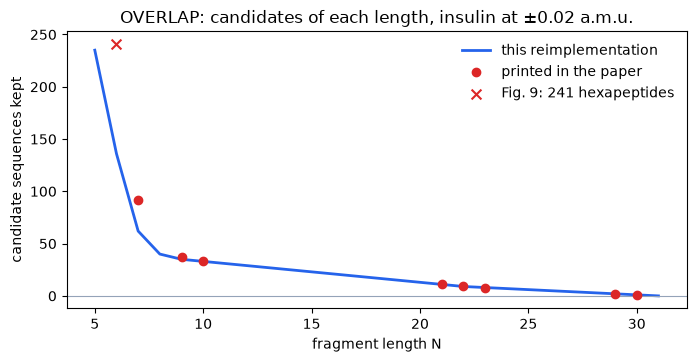

In [12]:
xs = sorted(sizes)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(xs, [sizes[k] for k in xs], color="#2563eb", lw=2, label="this reimplementation")
ax.scatter(list(paper), list(paper.values()), color="#dc2626", zorder=3, s=36, label="printed in the paper")
ax.scatter([6], [241], color="#dc2626", marker="x", s=50, zorder=3, label="Fig. 9: 241 hexapeptides")
ax.axhline(0, color="#94a3b8", lw=0.8)
ax.set_xlabel("fragment length N")
ax.set_ylabel("candidate sequences kept")
ax.set_title("OVERLAP: candidates of each length, insulin at ±0.02 a.m.u.")
ax.legend(frameon=False)
plt.show()

## The tryptophan misprint, demonstrated

Run the same lookup with the true tryptophan mass, and W (residue 186.079) falls within 0.02 of the
dipeptide G+E (186.064). Every "EG" in insulin then also reads as a W.

In [13]:
T_true = dict(T, W=round(204.0899 - W, 5))
c_true = masfrg(obs, T_true, W, 4)
print("with the printed W:", [len(comps[n]) for n in (1, 2, 3)], " (paper: 16, 66, 197)")
print("with the true W:   ", [len(c_true[n]) for n in (1, 2, 3)])
print("\nanswer with the true W:", run(obs, T_true, W).chains(25))

with the printed W: [16, 66, 197]  (paper: 16, 66, 197)
with the true W:    [17, 71, 208]

answer with the true W: ['AKPTOFFGREGCVJOJAEVJHSGCJHQNVF', 'AKPTOFFGRWCVJOJAEVJHSGCJHQNVF']


## Resolution: ±0.02 against ±0.05

"If the maximum observable mass was limited to 1000 a.m.u., and the maximum length of peptides to 9
links, the insulin problem could be solved with a resolution of ±0.02 a.m.u., but could not be
solved at ±0.05 a.m.u."

In [14]:
for tol in (0.02, 0.05):
    r = run(Observed(masses, tol_da=tol), T, W)
    chains = r.chains(20)
    print(f"±{tol}: {len(chains)} chains of 20 residues or more")
    for c in chains:
        print("   ", c)

±0.02: 2 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEQCCASVCSJOQJENOCN
±0.05: 12 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEKCCASVCSJOKJENOCN
    GJVEKCCASVCSJOQJENOCN
    GJVEQCCASVCSJOKJENOCN
    GJVEQCCASVCSJOQJENOCN
    NCONEJKOJSCVSACCKEVW
    NCONEJKOJSCVSACCQEVW
    NCONEJQOJSCVSACCKEVW
    NCONEJQOJSCVSACCQEVW


At ±0.05 glutamine and lysine (0.036 apart) can no longer be told apart, and every Q/K position of
the answer splits in two: four A chains, four B chains, and some debris. The answer is not unique, so
the problem is not solved.

## Practical considerations: noise


"Random noise masses can be tolerated in surprisingly large quantity because the resulting peptides
so seldom seem to overlap by chance ... If there were no more than about 4000 actually observed masses
in this range [100 to 1100], including all noise, the spectrum would not be too crowded."

In [15]:
for n_noise in (0, 500, 1000, 2000, 4000, 8000):
    noisy = add_noise(masses, n_random=n_noise, lo=100, hi=1100, seed=0)
    r = run(Observed(noisy, tol_da=0.02), T, W, max_list=300_000)
    chains = r.chains(15)
    ok = A in chains and (B in chains or B[::-1] in chains)
    print(f"{n_noise:5} noise masses ({len(noisy):5} in all): {len(chains)} chains of 15+, both insulin chains found: {ok}"
          + ("" if r.converged else f"  [{r.reason}]"))

    0 noise masses (  302 in all): 2 chains of 15+, both insulin chains found: True
  500 noise masses (  802 in all): 2 chains of 15+, both insulin chains found: True
 1000 noise masses ( 1302 in all): 2 chains of 15+, both insulin chains found: True
 2000 noise masses ( 2302 in all): 2 chains of 15+, both insulin chains found: True


 4000 noise masses ( 4302 in all): 2 chains of 15+, both insulin chains found: True


 8000 noise masses ( 8302 in all): 2 chains of 15+, both insulin chains found: True


The reimplementation tolerates even more than the paper expected: both chains still come back with
8000 random masses, twice the crowding the paper thought the limit.

## Practical considerations: longer proteins

"We conclude that as an ideal problem, with true masses only, and no noise, a protein of 100 links
could be reconstructed, using the masses of fragments up to only about 7 or 8 links long, having a
maximum molecular mass in the order of 800 a.m.u." Three random 100-residue proteins, exact masses,
every fragment below the mass limit:

In [16]:
import random
letters = sorted(T)
for seed in (1, 2, 3):
    rng = random.Random(seed)
    prot = "".join(rng.choice(letters) for _ in range(100))
    row = []
    for limit in (700, 800, 1000):
        r = run(Observed(ideal_masses([prot], 60, limit, T, W), tol_da=0.001), T, W,
                mass_limit=limit, max_list=300_000)
        found = any(c in (prot, prot[::-1]) for c in r.chains(100))
        row.append(f"{limit}: {'solved' if found else 'not solved'}")
    print(f"protein {seed}:  " + ",  ".join(row))

protein 1:  700: not solved,  800: solved,  1000: solved


protein 2:  700: not solved,  800: not solved,  1000: solved
protein 3:  700: solved,  800: solved,  1000: solved


The paper's estimate holds: with masses up to about 800-1000 a.m.u. a 100-residue protein comes back
from its fragment masses alone, and below that it may not.

## And today?

The paper ends: "The actual characteristics of a working system will determine the practicability
of the whole scheme." The rest of this repository asks that question of present-day instruments:
`simulate.py` makes the mass list of an LC-MS run of a non-specific digest, `modern.py` adapts the
reconstruction to it, and `scripts/real_pxd071026.py` runs it on a real pepsin digest of myoglobin.
The README summarises what came out: the accuracy is there (a few ppm), but a standard proteomics or
HDX run does not contain the many short, overlapping fragments the method lives on.